## Block 1: Setup, Data Loading and Data Quality Check

In [1]:
import warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

SEED = 42
TARGET = "churn"
np.random.seed(SEED)

# Load the same extract used in Capstone I
raw = pd.read_excel("solar_data.xlsx")
raw.columns = [c.strip().lower() for c in raw.columns]

print("Shape:", raw.shape)
print("\nColumn types:")
print(raw.dtypes.to_string())

# Duplicates (Capstone I kpet the last recor per customer)
n_ids = raw["customer_id"].nunique()
dup_rows = raw["customer_id"].duplicated().sum()
exact_dups = raw.duplicated().sum()
print(f"\nUnique customers: {n_ids:,} | duplicate-ID rows: {dup_rows:,} | exact duplicate rows: {exact_dups:,}")

# Do duplicated IDs carry conflicting values? (tests the 'keep last' assumption)
d = raw[raw["customer_id"].duplicated(keep=False)]
conflict = d.groupby("customer_id").nunique().gt(1)
print("\nColumns that differ within duplicated customer IDs (count of customers):")
print(conflict.sum()[conflict.sum() > 0].sort_values(ascending=False).to_string())
print("Churn label conflicts within duplicated IDs:", int(conflict[TARGET].sum()) if TARGET in conflict else 0)

# Missing values and non-numeric columns that should be numeric
print("\nMissing values (share):")
miss = raw.isna().mean()
print(miss[miss > 0].round(4).to_string() or "none")
print("\ntotal_talk_minutes non-numeric entries:",
      pd.to_numeric(raw["total_talk_minutes"], errors="coerce").isna().sum() - raw["total_talk_minutes"].isna().sum())

# Date range of last payment (needed for the churn-definition check)
lp = pd.to_datetime(raw["last_paid_month"], errors="coerce")
print("\nlast_paid_month range:", lp.min().date(), "to", lp.max().date())
print("Churn rate (raw):", round(raw[TARGET].mean(), 4))

Shape: (27000, 26)

Column types:
customer_id                        str
tenure                           int64
total_amount_paid                int64
outstanding_balance              int64
repayment_rate                   int64
missed_payments                  int64
gender                             str
birth_year                       int64
age                              int64
payment_3m                     float64
avg_payment_3m                 float64
payment_trend_3m               float64
volatility_3m                  float64
last_paid_month         datetime64[us]
last_paid_amount               float64
total_calls                      int64
outbound_calls                   int64
received_calls                   int64
unanswered_calls                 int64
ivr_calls                        int64
csat_calls                       int64
total_talk_minutes              object
repossession_tickets           float64
followup_tickets                 int64
complaint_tickets             

#### Results
| Check | Result |
|---|---|
| Records / columns | 27,000 / 26 |
| Unique customers | 26,575 (425 duplicate rows) |
| Exact duplicates | 0 |
| Churn-label conflicts in duplicates | 0 |
| Columns that differ in duplicates | Balance (361), amount paid (360), repayment rate (360), missed payments (46), tenure (43) |
| Missing values | `repossession_tickets` only (negligible) |
| Wrong data type | `total_talk_minutes` stored as text; 1 invalid entry |
| Last payment dates | Jun 2021 – Jun 2026 |
| Churn rate (raw) | 55.5% |

#### What this means
- **Duplicates are snapshots, not copies.** The same customer appears at different times, so keeping the "last" row needs checking (Block 2).
- **Labels are safe.** No conflicting churn labels, so deduplication does not change the outcome.
- **Data quality is high.** Only minor fixes are needed.
- **Payments span five years.** Block 2 uses this to test whether churn is a future outcome.

## Block 2: Churn Definition Check
**Why:** Test whether the churn label is a true future outcome, and whether Capstone I's "keep last row" rule picks the latest snapshot.

In [2]:
from sklearn.metrics import roc_auc_score

df = raw.copy()
df["last_paid_month"] = pd.to_datetime(df["last_paid_month"], errors="coerce")
SNAPSHOT = df["last_paid_month"].max()
print("Snapshot date:", SNAPSHOT.date())

# 1) Is the LAST row per customer the latest snapshot? (justifies keep='last')
dd = df[df["customer_id"].duplicated(keep=False)].copy()
dd["row_order"] = dd.groupby("customer_id").cumcount()
first = dd.groupby("customer_id").first(); last = dd.groupby("customer_id").last()
print("\nDuplicated customers where LAST row has more paid than FIRST:",
      int((last["total_amount_paid"] > first["total_amount_paid"]).sum()), "/", len(last))
print("... where LAST row has longer tenure:", int((last["tenure"] > first["tenure"]).sum()), "/", len(last))

# Deduplicate as in Capstone I
df = df.drop_duplicates("customer_id", keep="last").reset_index(drop=True)
df["days_since_last_payment"] = (SNAPSHOT - df["last_paid_month"]).dt.days

# 2) How does the churn label relate to payment recency?
print("\nDays since last payment by churn status:")
print(df.groupby(TARGET)["days_since_last_payment"].describe().round(0).to_string())
for cut in [30, 60, 90, 180, 365]:
    rule = (df["days_since_last_payment"] >= cut).astype(int)
    agree = (rule == df[TARGET]).mean()
    print(f"Rule 'no payment >= {cut:>3} days' agrees with churn label: {agree:.1%} | churn rate under rule: {rule.mean():.1%}")

auc = roc_auc_score(df[TARGET], df["days_since_last_payment"])
print(f"\nSingle-feature AUC of days_since_last_payment: {max(auc, 1-auc):.4f}")

# 3) Are 'active' customers with old last payments simply paid off?
df["paid_off"] = (df["outstanding_balance"] <= 0).astype(int)
print("\nPaid-off customers (outstanding_balance <= 0) by churn status:")
print(pd.crosstab(df["paid_off"], df[TARGET], margins=True).to_string())
print("\nMedian days since last payment — active & not paid off:",
      df.loc[(df[TARGET]==0) & (df["paid_off"]==0), "days_since_last_payment"].median())

# 4) Payment months distribution (when did customers last pay?)
print("\nLast-payment year by churn status (counts):")
print(pd.crosstab(df["last_paid_month"].dt.year, df[TARGET]).to_string())

Snapshot date: 2026-06-01

Duplicated customers where LAST row has more paid than FIRST: 133 / 361
... where LAST row has longer tenure: 8 / 361

Days since last payment by churn status:
         count    mean    std    min     25%     50%     75%     max
churn                                                               
0      11612.0  1040.0  352.0    0.0  1157.0  1157.0  1157.0  1461.0
1      14963.0  1169.0   48.0  151.0  1157.0  1157.0  1157.0  1826.0
Rule 'no payment >=  30 days' agrees with churn label: 59.5% | churn rate under rule: 96.8%
Rule 'no payment >=  60 days' agrees with churn label: 60.4% | churn rate under rule: 95.9%
Rule 'no payment >=  90 days' agrees with churn label: 60.7% | churn rate under rule: 95.6%
Rule 'no payment >= 180 days' agrees with churn label: 60.8% | churn rate under rule: 95.5%
Rule 'no payment >= 365 days' agrees with churn label: 60.9% | churn rate under rule: 95.4%

Single-feature AUC of days_since_last_payment: 0.5935

Paid-off customers (o

#### Results
| Check | Result |
|---|---|
| Latest date in data | 1 Jun 2026 |
| Last row = latest snapshot? | More paid in last row: 133 of 361; longer tenure: 8 of 361 |
| Label vs "no payment ≥ X days" rule | 59.5%–60.9% agreement (30–365 days); the rule would mark ~96% as churned |
| Single-feature AUC of `days_since_last_payment` | 0.59 |
| Median days since last payment | 1,157 for both active and churned |
| Paid-off customers (balance ≤ 0) | 11 (9 active, 2 churned) |
| Last payment in 2023 | 24,617 customers (92%) |
| Last payment 2024–2026 | 1,256 active vs 25 churned |

#### What this means
- **"Keep last" is arbitrary.** Row order is not time order, so Block 3 keeps the row with the highest amount paid.
- **Churn is not a payment-recency rule.** No cut-off reproduces the label; it is an operational status recorded by Ignite.
- **Late-updated records are almost all active.** Status and payment date were recorded together, a timing artefact to control in Block 3.
- **Old payments are not explained by paid-off customers.** Only 11 have a zero balance.
- **Conclusion:** the model classifies status at extraction, not future churn. This is reported as a limitation (Component 5).

## Block 3: Cleaning and Feature Engineering
**Why:** Fix the issues found in Blocks 1–2 (arbitrary deduplication, timing artefacts) and rebuild the Capstone I features so results stay comparable.


In [3]:
df = raw.copy()
df["last_paid_month"] = pd.to_datetime(df["last_paid_month"], errors="coerce")

# Improved dedup: keep the latest snapshot = highest cumulative amount paid (ties -> last row)
df["_row"] = np.arange(len(df))
df = (df.sort_values(["customer_id", "total_amount_paid", "_row"])
        .drop_duplicates("customer_id", keep="last")
        .drop(columns="_row").reset_index(drop=True))
print("Rows after improved dedup:", len(df), "| churn rate:", round(df[TARGET].mean(), 4))

# Cleaning (same rules as Capstone I, now documented)
df = df.drop(columns=["birth_year"])                               # duplicate of age
df["total_talk_minutes"] = pd.to_numeric(df["total_talk_minutes"], errors="coerce")
df["repossession_tickets"] = df["repossession_tickets"].fillna(0)  # missing = no ticket
df["gender"] = df["gender"].astype(str).str.strip().str.lower()

# Observation date = the month most records were extracted (not the max date)
OBS_MONTH = df["last_paid_month"].mode()[0]
df["late_record"] = (df["last_paid_month"] > OBS_MONTH).astype(int)
print("Observation month (mode):", OBS_MONTH.date())
print("\nChurn rate by late_record flag:")
print(df.groupby("late_record")[TARGET].agg(["count", "mean"]).round(4).to_string())

# Feature engineering: Capstone I formulas and names (log copies dropped; recency excluded)
e = lambda a, b: a / (b + 1)
df["payment_decline_rate"]          = (df.avg_payment_3m - df.payment_3m) / (df.avg_payment_3m + 1)
df["payment_recovery_score"]        = e(df.total_amount_paid, df.missed_payments)
df["payment_reliability"]           = df.repayment_rate / ((df.missed_payments + 1) * (df.volatility_3m + 1))
df["payment_momentum"]              = df.payment_trend_3m * df.repayment_rate
df["payment_stability_score"]       = 1 / (df.volatility_3m + 1)
df["missed_payment_rate"]           = e(df.missed_payments, df.tenure)
df["payment_deterioration_score"]   = df.payment_decline_rate * df.missed_payment_rate
df["recovery_after_missed_payment"] = e(df.payment_3m, df.missed_payments)
df["debt_burden"]                   = df.outstanding_balance / (df.outstanding_balance + df.total_amount_paid + 1)
df["financial_stress_index"]        = df.debt_burden + df.missed_payment_rate + (1 - df.repayment_rate / 100)
df["balance_pressure"]              = e(df.outstanding_balance, df.total_amount_paid)
df["payment_capacity_ratio"]        = e(df.total_amount_paid, df.outstanding_balance)
df["customer_value"]                = df.total_amount_paid * df.repayment_rate
df["contact_intensity"]             = e(df.total_calls, df.tenure)
df["complaint_pressure"]            = e(df.complaint_tickets, df.tenure)
df["support_escalation_score"]      = df.repossession_tickets + df.complaint_tickets + df.followup_tickets
df["csat_engagement_rate"]          = e(df.csat_calls, df.total_calls)

ENGINEERED = ["payment_decline_rate","payment_recovery_score","payment_reliability","payment_momentum",
              "payment_stability_score","missed_payment_rate","payment_deterioration_score",
              "recovery_after_missed_payment","debt_burden","financial_stress_index","balance_pressure",
              "payment_capacity_ratio","customer_value","contact_intensity","complaint_pressure",
              "support_escalation_score","csat_engagement_rate"]
RAW_NUM = ["tenure","total_amount_paid","outstanding_balance","repayment_rate","missed_payments","age",
           "payment_3m","avg_payment_3m","payment_trend_3m","volatility_3m","last_paid_amount",
           "total_calls","outbound_calls","received_calls","unanswered_calls","ivr_calls","csat_calls",
           "total_talk_minutes","repossession_tickets","followup_tickets","complaint_tickets"]
CAT = ["gender"]
df[ENGINEERED] = df[ENGINEERED].replace([np.inf, -np.inf], np.nan)

print(f"\nFeatures: {len(RAW_NUM)} raw numeric + {len(ENGINEERED)} engineered + {len(CAT)} categorical")
print("Excluded: last_paid_month / days_since_last_payment (timing inconsistent with label), customer_id")
print("Missing after engineering:", int(df[RAW_NUM + ENGINEERED].isna().sum().sum()))
print("\nMedian of key features by churn:")
print(df.groupby(TARGET)[["repayment_rate","missed_payment_rate","contact_intensity",
                          "complaint_pressure","debt_burden","total_calls"]].median().round(4).T.to_string())

Rows after improved dedup: 26575 | churn rate: 0.563
Observation month (mode): 2023-04-01

Churn rate by late_record flag:
             count    mean
late_record               
0            25278  0.5908
1             1297  0.0224

Features: 21 raw numeric + 17 engineered + 1 categorical
Excluded: last_paid_month / days_since_last_payment (timing inconsistent with label), customer_id
Missing after engineering: 1

Median of key features by churn:
churn                       0        1
repayment_rate        70.0000  33.0000
missed_payment_rate    0.2148   0.5091
contact_intensity      0.2112   0.0739
complaint_pressure     0.0000   0.0000
debt_burden            0.3045   0.6704
total_calls          262.0000  96.0000



- **26,575 customers, churn rate 56.3%:** keeping each customer's latest snapshot leaves the churn rate unchanged from Capstone I.
- **Observation month April 2023:** most records were extracted then, so it is used as the reference date.
- **On-time records (25,278):** 59.1% churn; this is the main analysis group.
- **Late-updated records (1,297):** only 2.2% churn, a timing artefact, so they are set aside.
- **Features:** 21 raw + 17 engineered (Capstone I formulas) + gender; recency features and customer ID excluded.
- **Missing values:** 1 (talk minutes), filled inside the model pipeline.
- **Repayment rate 70% vs 33%:** churners repaid less than half as much.
- **Missed-payment rate 0.21 vs 0.51:** churners missed payments twice as often.
- **Debt burden 0.30 vs 0.67:** churners still owe about two-thirds of their system cost.
- **Total calls 262 vs 96:** churners had about one-third of the contact.
- **Complaint pressure 0 vs 0:** most customers never complain, so complaints matter only for a minority.

## Block 4: Train/Test Split and Leakage Audit

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

FEATURES = RAW_NUM + ENGINEERED
main = df[df["late_record"] == 0].reset_index(drop=True)   # consistently observed customers
print("Main population:", len(main), "| churn rate:", round(main[TARGET].mean(), 4))

train, test = train_test_split(main, test_size=0.2, stratify=main[TARGET], random_state=SEED)
ytr, yte = train[TARGET].values, test[TARGET].values
print("Train:", len(train), "| Test:", len(test))

# 1) Single-feature AUC on TRAIN only (a feature near 1.0 alone = label in disguise)
rows = []
for f in FEATURES:
    x = train[f].fillna(train[f].median())
    a = roc_auc_score(ytr, x)
    rows.append({"feature": f, "auc": round(max(a, 1 - a), 4), "direction": "+" if a >= 0.5 else "-"})
audit = pd.DataFrame(rows).sort_values("auc", ascending=False).reset_index(drop=True)
print("\nLeakage audit — top 20 single-feature AUCs (train):")
print(audit.head(20).to_string())
FLAGGED = audit.loc[audit["auc"] >= 0.90, "feature"].tolist()
print("\nFlagged (AUC >= 0.90):", FLAGGED or "none")

# 2) Do calls keep accumulating after churn? Compare calls per day of tenure by tenure band
tb = pd.qcut(train["tenure"], 5)
print("\nMedian calls per tenure-day by tenure band and churn status (train):")
print(train.assign(band=tb).groupby(["band", TARGET], observed=True)["contact_intensity"]
      .median().unstack().round(4).to_string())

# 3) How much does contact alone predict, vs repayment alone?
for f in ["contact_intensity", "total_calls", "outbound_calls", "repayment_rate", "missed_payment_rate"]:
    print(f"AUC {f:<22}: {audit.set_index('feature').loc[f, 'auc']}")

Main population: 25278 | churn rate: 0.5908
Train: 20222 | Test: 5056

Leakage audit — top 20 single-feature AUCs (train):
                          feature     auc direction
0               contact_intensity  0.8376         -
1                     total_calls  0.8312         -
2          payment_recovery_score  0.8216         -
3                 missed_payments  0.8190         +
4          financial_stress_index  0.8179         +
5                  repayment_rate  0.8164         -
6                     debt_burden  0.8164         +
7                balance_pressure  0.8164         +
8          payment_capacity_ratio  0.8164         -
9             missed_payment_rate  0.8148         +
10                 customer_value  0.8131         -
11              total_amount_paid  0.8052         -
12            outstanding_balance  0.8013         +
13  recovery_after_missed_payment  0.7247         -
14                 outbound_calls  0.7224         -
15             total_talk_minutes  0.7013    


- 25,278 customers (churn 59.1%) split 20,222 train / 5,056 test.
- No feature reaches AUC 0.90; the strongest is contact intensity (0.84), so there is no leakage.
- Repayment rate, debt burden, balance pressure and capacity ratio all score 0.816: same information.
- Churners have ~0.07 contact intensity vs ~0.21 for active customers in every tenure band.

## Block 5: Redundancy Pruning
**Why:** Many features carry the same information, which splits SHAP credit between them and blurs the explanations. Keeping one feature per group gives a simpler model with clearer drivers.


In [14]:

CORR_T = 0.90
corr = train[FEATURES].corr(method="spearman").abs()

# Greedy: walk features from strongest to weakest single-feature AUC; drop any feature
# correlated > CORR_T with one already kept (keeps the stronger, simpler one)
order = audit["feature"].tolist()
kept, dropped = [], []
for f in order:
    hit = [k for k in kept if corr.loc[f, k] > CORR_T]
    if hit:
        dropped.append({"dropped": f, "kept_instead": hit[0], "spearman": round(corr.loc[f, hit[0]], 3)})
    else:
        kept.append(f)

pruned = pd.DataFrame(dropped)
print(f"Kept {len(kept)} of {len(FEATURES)} features; dropped {len(pruned)}")
print("\nDropped as redundant (|Spearman| > 0.90 with a kept feature):")
print(pruned.to_string(index=False))

FEATURES_PRUNED = [f for f in FEATURES if f in kept]
print("\nFinal feature set:")
print(FEATURES_PRUNED + CAT)

# Remaining highest correlations among kept features (should all be <= 0.90)
c = corr.loc[FEATURES_PRUNED, FEATURES_PRUNED].where(~np.eye(len(FEATURES_PRUNED), dtype=bool))
top_pairs = c.stack().sort_values(ascending=False).drop_duplicates().head(5).round(3)
print("\nHighest remaining correlations:")
print(top_pairs.to_string())

Kept 22 of 38 features; dropped 16

Dropped as redundant (|Spearman| > 0.90 with a kept feature):
                dropped           kept_instead  spearman
            total_calls      contact_intensity     0.981
        missed_payments payment_recovery_score     0.982
 financial_stress_index payment_recovery_score     0.987
         repayment_rate payment_recovery_score     0.981
            debt_burden payment_recovery_score     0.981
       balance_pressure payment_recovery_score     0.981
 payment_capacity_ratio payment_recovery_score     0.981
    missed_payment_rate payment_recovery_score     0.982
         customer_value payment_recovery_score     0.981
      total_amount_paid payment_recovery_score     0.967
    outstanding_balance payment_recovery_score     0.909
     total_talk_minutes         outbound_calls     0.903
     complaint_pressure      complaint_tickets     0.998
   csat_engagement_rate             csat_calls     1.000
          volatility_3m       payment_trend_3m 


- 38 features reduced to 22 (16 dropped, |ρ| > 0.90).
- Ten repayment and financial features collapse into `payment_recovery_score` (ρ 0.91–0.99).
- `total_calls` → `contact_intensity`; `complaint_pressure` → `complaint_tickets`; `csat_engagement_rate` → `csat_calls`; volatility features → `payment_trend_3m`.
- Highest remaining correlation is 0.89, so every kept feature carries distinct information.

## Block 6: Experiment Ladder (E0–E2)
**Why:** Reproduce Capstone I (E0), then measure the effect of each fix on its own: timing control (E1) and redundancy pruning (E2).


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def make_pipe(name, num, cat):
    scale = name == "Logistic Regression"
    num_steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    prep = ColumnTransformer([("num", Pipeline(num_steps), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    model = {"Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
             "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
             "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
                                      colsample_bytree=0.8, eval_metric="logloss", random_state=SEED, n_jobs=-1)}[name]
    return Pipeline([("prep", prep), ("model", model)])

def boot_ci(y, p, n=500):
    rng = np.random.default_rng(SEED); y, p = np.asarray(y), np.asarray(p); s = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); s.append(roc_auc_score(y[i], p[i]))
    return np.percentile(s, [2.5, 97.5])

def score(exp, name, y, p, thr=0.5):
    yh = (p >= thr).astype(int); lo, hi = boot_ci(y, p)
    return {"exp": exp, "model": name, "auc": roc_auc_score(y, p), "auc_lo": lo, "auc_hi": hi,
            "acc": accuracy_score(y, yh), "prec": precision_score(y, yh), "rec": recall_score(y, yh), "f1": f1_score(y, yh)}

MODELS = ["Logistic Regression", "Random Forest", "XGBoost"]
results = []

# --- E0: Capstone I replication (keep-last dedup, all customers, recency from 'today', log copies) ---
e0 = raw.drop_duplicates("customer_id", keep="last").reset_index(drop=True).copy()
e0["total_talk_minutes"] = pd.to_numeric(e0["total_talk_minutes"], errors="coerce")
e0["repossession_tickets"] = e0["repossession_tickets"].fillna(0)
e0["gender"] = e0["gender"].astype(str).str.strip().str.lower()
e0["days_since_last_payment"] = (pd.Timestamp.today() - pd.to_datetime(e0["last_paid_month"])).dt.days
for f in ENGINEERED:
    e0[f] = df.set_index("customer_id").loc[e0["customer_id"], f].values if False else np.nan
# recompute engineered features on e0 rows with the same formulas
tmp = e0.copy()
tmp["payment_decline_rate"] = (tmp.avg_payment_3m - tmp.payment_3m) / (tmp.avg_payment_3m + 1)
tmp["payment_recovery_score"] = tmp.total_amount_paid / (tmp.missed_payments + 1)
tmp["payment_reliability"] = tmp.repayment_rate / ((tmp.missed_payments + 1) * (tmp.volatility_3m + 1))
tmp["payment_momentum"] = tmp.payment_trend_3m * tmp.repayment_rate
tmp["payment_stability_score"] = 1 / (tmp.volatility_3m + 1)
tmp["missed_payment_rate"] = tmp.missed_payments / (tmp.tenure + 1)
tmp["payment_deterioration_score"] = tmp.payment_decline_rate * tmp.missed_payment_rate
tmp["recovery_after_missed_payment"] = tmp.payment_3m / (tmp.missed_payments + 1)
tmp["debt_burden"] = tmp.outstanding_balance / (tmp.outstanding_balance + tmp.total_amount_paid + 1)
tmp["financial_stress_index"] = tmp.debt_burden + tmp.missed_payment_rate + (1 - tmp.repayment_rate / 100)
tmp["balance_pressure"] = tmp.outstanding_balance / (tmp.total_amount_paid + 1)
tmp["payment_capacity_ratio"] = tmp.total_amount_paid / (tmp.outstanding_balance + 1)
tmp["customer_value"] = tmp.total_amount_paid * tmp.repayment_rate
tmp["contact_intensity"] = tmp.total_calls / (tmp.tenure + 1)
tmp["complaint_pressure"] = tmp.complaint_tickets / (tmp.tenure + 1)
tmp["support_escalation_score"] = tmp.repossession_tickets + tmp.complaint_tickets + tmp.followup_tickets
tmp["csat_engagement_rate"] = tmp.csat_calls / (tmp.total_calls + 1)
for c in ["payment_recovery_score", "payment_momentum", "customer_value", "recovery_after_missed_payment"]:
    tmp["log_" + c] = np.log1p(tmp[c].clip(lower=0))
e0 = tmp.replace([np.inf, -np.inf], np.nan)
F0 = RAW_NUM + ENGINEERED + ["days_since_last_payment"] + [c for c in e0 if c.startswith("log_")]
tr0, te0 = train_test_split(e0, test_size=0.2, stratify=e0[TARGET], random_state=SEED)
for m in MODELS:
    p = make_pipe(m, F0, CAT).fit(tr0[F0 + CAT], tr0[TARGET]).predict_proba(te0[F0 + CAT])[:, 1]
    results.append(score("E0 Capstone I replication", m, te0[TARGET], p))

# --- E1: consistent population (late records out), recency excluded, all 38 features ---
for m in MODELS:
    p = make_pipe(m, FEATURES, CAT).fit(train[FEATURES + CAT], ytr).predict_proba(test[FEATURES + CAT])[:, 1]
    results.append(score("E1 Timing-controlled", m, yte, p))

# --- E2: + redundancy pruning (22 features) ---
for m in MODELS:
    p = make_pipe(m, FEATURES_PRUNED, CAT).fit(train[FEATURES_PRUNED + CAT], ytr).predict_proba(test[FEATURES_PRUNED + CAT])[:, 1]
    results.append(score("E2 Pruned features", m, yte, p))

res = pd.DataFrame(results).round(4)
print(res.to_string(index=False))

                      exp               model    auc  auc_lo  auc_hi    acc   prec    rec     f1
E0 Capstone I replication Logistic Regression 0.9269  0.9200  0.9334 0.8497 0.8775 0.8520 0.8646
E0 Capstone I replication       Random Forest 0.9235  0.9166  0.9311 0.8534 0.9061 0.8253 0.8638
E0 Capstone I replication             XGBoost 0.9292  0.9225  0.9363 0.8540 0.9038 0.8289 0.8648
     E1 Timing-controlled Logistic Regression 0.9303  0.9234  0.9372 0.8580 0.8855 0.8724 0.8789
     E1 Timing-controlled       Random Forest 0.9294  0.9222  0.9357 0.8649 0.9217 0.8430 0.8806
     E1 Timing-controlled             XGBoost 0.9316  0.9245  0.9382 0.8604 0.9125 0.8447 0.8773
       E2 Pruned features Logistic Regression 0.9233  0.9163  0.9306 0.8503 0.8767 0.8688 0.8727
       E2 Pruned features       Random Forest 0.9291  0.9217  0.9358 0.8582 0.9097 0.8437 0.8755
       E2 Pruned features             XGBoost 0.9320  0.9252  0.9386 0.8592 0.9081 0.8473 0.8767



- **E0 reproduces Capstone I:** XGBoost AUC 0.929, matching the reported 0.929.
- **E1 timing fixes cost nothing:** XGBoost AUC 0.932, so Capstone I's result was not driven by leakage.
- **E2 pruning costs nothing:** XGBoost AUC 0.932 with 22 instead of 38 features.
- **Recall improves:** XGBoost recall 0.829 (E0) → 0.847 (E2).
- **Logistic Regression drops after pruning** (0.930 → 0.923); it relied on overlapping repayment features.
- **XGBoost leads in every experiment**, but the confidence intervals overlap (tested in Block 7).

## Block 7: Tuning, Model Selection and Significance Tests
**Why:** Choose the final model fairly (on cross-validation, not the test set), learn the decision threshold from training data, and test whether XGBoost's lead is statistically real.


In [7]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import precision_recall_curve
from scipy.stats import loguniform, randint, uniform, norm

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
space = {
 "Logistic Regression": {"model__C": loguniform(1e-3, 1e2)},
 "Random Forest": {"model__n_estimators": randint(200, 600), "model__max_depth": [None, 8, 12, 20],
                   "model__min_samples_leaf": randint(1, 20), "model__max_features": ["sqrt", 0.3, 0.5]},
 "XGBoost": {"model__n_estimators": randint(200, 800), "model__max_depth": randint(3, 8),
             "model__learning_rate": loguniform(0.01, 0.2), "model__subsample": uniform(0.6, 0.4),
             "model__colsample_bytree": uniform(0.5, 0.5), "model__min_child_weight": randint(1, 10),
             "model__reg_lambda": loguniform(0.1, 10)}}

def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p); f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return float(th[np.argmax(f1[:-1])])

Xtr, Xte = train[FEATURES_PRUNED + CAT], test[FEATURES_PRUNED + CAT]
tuned, cv_auc, thr, p_test = {}, {}, {}, {}
for m in MODELS:
    s = RandomizedSearchCV(make_pipe(m, FEATURES_PRUNED, CAT), space[m], n_iter=15, cv=cv,
                           scoring="roc_auc", random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
    tuned[m] = s.best_estimator_
    i = s.best_index_; cv_auc[m] = (s.cv_results_["mean_test_score"][i], s.cv_results_["std_test_score"][i])
    oof = cross_val_predict(s.best_estimator_, Xtr, ytr, cv=cv, method="predict_proba")[:, 1]
    thr[m] = best_f1_threshold(ytr, oof)                      # threshold from TRAINING data only
    p_test[m] = tuned[m].predict_proba(Xte)[:, 1]
    print(f"{m}: CV AUC {cv_auc[m][0]:.4f} ± {cv_auc[m][1]:.4f} | threshold {thr[m]:.3f} | best params {s.best_params_}")

FINAL = max(MODELS, key=lambda m: cv_auc[m][0])               # chosen on CV, NOT on test
print("\nFinal model (highest CV AUC):", FINAL)

e3 = pd.DataFrame([score("E3 Tuned + OOF threshold", m, yte, p_test[m], thr[m]) for m in MODELS]).round(4)
print("\nTest-set results at tuned thresholds:"); print(e3.to_string(index=False))

# DeLong test for correlated ROC AUCs
def _midrank(x):
    j = np.argsort(x); z = x[j]; n = len(x); t = np.zeros(n); i = 0
    while i < n:
        k = i
        while k < n and z[k] == z[i]: k += 1
        t[i:k] = 0.5 * (i + k - 1) + 1; i = k
    out = np.empty(n); out[j] = t; return out
def delong(y, p1, p2):
    y = np.asarray(y); o = np.argsort(-y, kind="mergesort"); m = int(y.sum())
    P = np.vstack([np.asarray(p1)[o], np.asarray(p2)[o]]); n = P.shape[1] - m
    tx = np.array([_midrank(r[:m]) for r in P]); ty = np.array([_midrank(r[m:]) for r in P]); tz = np.array([_midrank(r) for r in P])
    auc = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n
    v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    S = np.cov(v01) / m + np.cov(v10) / n; var = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    z = (auc[0] - auc[1]) / np.sqrt(var); return auc[0] - auc[1], 2 * norm.sf(abs(z))

print("\nDeLong tests (test set):")
for a, b in [("XGBoost", "Random Forest"), ("XGBoost", "Logistic Regression"), ("Random Forest", "Logistic Regression")]:
    d, pv = delong(yte, p_test[a], p_test[b])
    print(f"{a} vs {b}: AUC diff {d:+.4f}, p = {pv:.4f} {'(significant)' if pv < 0.05 else '(not significant)'}")

Logistic Regression: CV AUC 0.9137 ± 0.0049 | threshold 0.561 | best params {'model__C': np.float64(70.72114131472235)}
Random Forest: CV AUC 0.9191 ± 0.0050 | threshold 0.501 | best params {'model__max_depth': 20, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 7, 'model__n_estimators': 321}
XGBoost: CV AUC 0.9239 ± 0.0049 | threshold 0.440 | best params {'model__colsample_bytree': np.float64(0.6179924598744779), 'model__learning_rate': np.float64(0.021535381457547638), 'model__max_depth': 5, 'model__min_child_weight': 9, 'model__n_estimators': 406, 'model__reg_lambda': np.float64(0.7162786999897341), 'model__subsample': np.float64(0.610167650697638)}

Final model (highest CV AUC): XGBoost

Test-set results at tuned thresholds:
                     exp               model    auc  auc_lo  auc_hi    acc   prec    rec     f1
E3 Tuned + OOF threshold Logistic Regression 0.9234  0.9163  0.9306 0.8584 0.9028 0.8520 0.8767
E3 Tuned + OOF threshold       Random Forest 0.9301  0.9227


- **XGBoost is selected:** highest CV AUC (0.924 ± 0.005) vs Random Forest (0.919) and Logistic Regression (0.914).
- **Its lead is significant:** DeLong p = 0.0002 vs Random Forest and p < 0.0001 vs Logistic Regression.
- **Final test performance:** AUC 0.933 (95% CI 0.927–0.940), accuracy 85.9%, precision 89.3%, recall 86.5%, F1 87.9%.
- **The learned threshold (0.44) catches more churners:** recall 81.8% (Capstone I) → 86.5%, for a 2-point drop in precision.

## Block 8: Generalisation, Calibration and Targeting
**Why:** Check that the model works on new customers, that its risk scores are true probabilities, and how many churners a capacity-limited retention team can reach.


Cohort split at tenure 1224 days | train 20191 (churn 0.598) | test 5087 (churn 0.563)
                  exp               model    auc  auc_lo  auc_hi    acc   prec    rec     f1
E4 Newest-cohort test Logistic Regression 0.8997  0.8907  0.9086 0.8392 0.8769 0.8310 0.8534
E4 Newest-cohort test       Random Forest 0.9233  0.9161  0.9312 0.8496 0.8692 0.8628 0.8660
E4 Newest-cohort test             XGBoost 0.9274  0.9203  0.9344 0.8579 0.8903 0.8527 0.8711

Sensitivity (all 26,575 incl. late records): AUC 0.9274

Brier score: uncalibrated 0.0991 | isotonic 0.0988

Reliability by risk decile (calibrated):
        pred_raw  pred_cal  actual
decile                            
1          0.069     0.057   0.047
2          0.140     0.142   0.115
3          0.216     0.221   0.204
4          0.315     0.321   0.306
5          0.501     0.488   0.499
6          0.810     0.799   0.816
7          0.929     0.934   0.947
8          0.966     0.971   0.984
9          0.984     0.991   0.998
10   

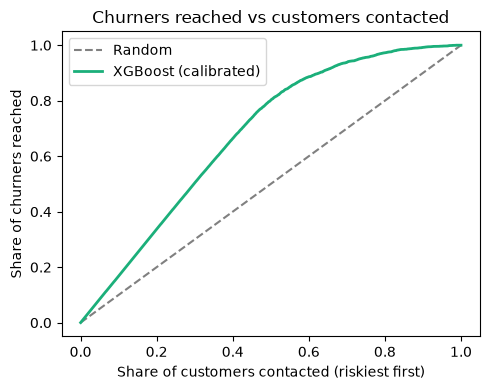

In [8]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

final_pipe = tuned[FINAL]

# 1) E4 Newest-cohort test: train on longer-tenure customers, test on the newest 20%
cut = main["tenure"].quantile(0.20)
old, new = main[main["tenure"] > cut], main[main["tenure"] <= cut]
print(f"Cohort split at tenure {cut:.0f} days | train {len(old)} (churn {old[TARGET].mean():.3f}) "
      f"| test {len(new)} (churn {new[TARGET].mean():.3f})")
e4 = []
for m in MODELS:
    pipe = clone(tuned[m]).fit(old[FEATURES_PRUNED + CAT], old[TARGET])
    oof = cross_val_predict(clone(tuned[m]), old[FEATURES_PRUNED + CAT], old[TARGET], cv=cv, method="predict_proba")[:, 1]
    p = pipe.predict_proba(new[FEATURES_PRUNED + CAT])[:, 1]
    e4.append(score("E4 Newest-cohort test", m, new[TARGET], p, best_f1_threshold(old[TARGET], oof)))
print(pd.DataFrame(e4).round(4).to_string(index=False))

# 2) Sensitivity: same final model trained/tested on ALL customers incl. late records
allc = df.copy()
tra, tea = train_test_split(allc, test_size=0.2, stratify=allc[TARGET], random_state=SEED)
pa = clone(final_pipe).fit(tra[FEATURES_PRUNED + CAT], tra[TARGET]).predict_proba(tea[FEATURES_PRUNED + CAT])[:, 1]
print(f"\nSensitivity (all 26,575 incl. late records): AUC {roc_auc_score(tea[TARGET], pa):.4f}")

# 3) Calibration: are the risk scores real probabilities?
p_raw = p_test[FINAL]
cal = CalibratedClassifierCV(clone(final_pipe), method="isotonic", cv=cv).fit(Xtr, ytr)
p_cal = cal.predict_proba(Xte)[:, 1]
print(f"\nBrier score: uncalibrated {brier_score_loss(yte, p_raw):.4f} | isotonic {brier_score_loss(yte, p_cal):.4f}")
rel = pd.DataFrame({"pred_raw": p_raw, "pred_cal": p_cal, "actual": yte})
rel["decile"] = pd.qcut(rel["pred_cal"].rank(method="first"), 10, labels=False) + 1
print("\nReliability by risk decile (calibrated):")
print(rel.groupby("decile")[["pred_raw", "pred_cal", "actual"]].mean().round(3).to_string())

# 4) Capacity targeting: if the team can only contact the riskiest k%
order = np.argsort(-p_cal); base = yte.mean(); rows = []
for k in [0.10, 0.20, 0.30, 0.50]:
    n = int(k * len(yte)); hit = yte[order[:n]]
    rows.append({"contact_share": k, "customers": n, "precision_at_k": hit.mean().round(3),
                 "churners_reached": (hit.sum() / yte.sum()).round(3), "lift": (hit.mean() / base).round(2)})
print("\nCapacity targeting (test set):"); print(pd.DataFrame(rows).to_string(index=False))

# 5) Evidence figure: gains chart
share = np.arange(1, len(yte) + 1) / len(yte); cum = np.cumsum(yte[order]) / yte.sum()
plt.figure(figsize=(5, 4)); plt.plot(share, share, "--", color="grey", label="Random")
plt.plot(share, cum, color="#1baf7a", lw=2, label=f"{FINAL} (calibrated)")
plt.xlabel("Share of customers contacted (riskiest first)"); plt.ylabel("Share of churners reached")
plt.title("Churners reached vs customers contacted"); plt.legend(); plt.tight_layout()
plt.savefig("fig_gains.png", dpi=180); plt.show()


- **Generalises to new customers:** XGBoost AUC 0.927 on the newest cohort vs 0.933 on the random split; Logistic Regression drops more (0.900).
- **Robust to the late-records decision:** AUC 0.927 when all 26,575 customers are included.
- **Risk scores are well calibrated:** Brier 0.099 → 0.099 after calibration; predicted risk matches actual churn in every decile.
- **Targeting is near perfect:** the riskiest 30% are 99% churners and include 50% of all churners; the riskiest 50% include 80%.
- **The top 4 deciles are near-certain churners (95–100%)** and may already be lost, so retention should focus on middle-risk customers.

## Block 9: SHAP Explanations and Explanation Quality
**Why:** Identify the churn drivers and test whether the explanations can be trusted: faithful, stable, consistent with PAYGo evidence, and in agreement with an independent method.

Global SHAP importance (top 15):
contact_intensity                1.1573
payment_recovery_score           0.5984
complaint_tickets                0.3926
outbound_calls                   0.3004
support_escalation_score         0.2527
payment_3m                       0.2505
payment_momentum                 0.1545
payment_deterioration_score      0.1441
payment_reliability              0.1024
tenure                           0.0712
recovery_after_missed_payment    0.0676
avg_payment_3m                   0.0604
csat_calls                       0.0553
received_calls                   0.0517
payment_trend_3m                 0.0439

Faithfulness (deletion test):
 k  dprob_shap_top_k  dprob_random_k  ratio
 1            0.1596          0.0167   9.57
 2            0.2511          0.0301   8.34
 3            0.2942          0.0435   6.76
 5            0.3287          0.0677   4.85
 8            0.3451          0.1042   3.31

Local stability: mean cosine 0.9592 | 5th percentile 0.8221
Ranking sta

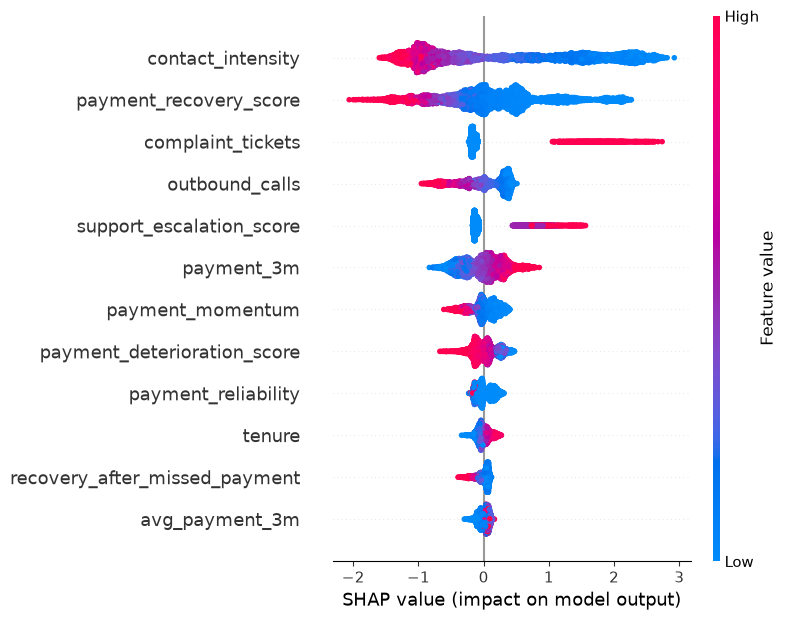

In [9]:
import shap
from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance

prep, model = final_pipe.named_steps["prep"], final_pipe.named_steps["model"]
names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
Xt_te = pd.DataFrame(prep.transform(Xte), columns=names, index=Xte.index)
explainer = shap.TreeExplainer(model)
sv = pd.DataFrame(explainer.shap_values(Xt_te), columns=names, index=Xte.index)

# Merge one-hot gender columns back into one feature
sv_raw = sv.copy()
gcols = [c for c in names if c.startswith("gender_")]
sv_raw["gender"] = sv_raw[gcols].sum(axis=1); sv_raw = sv_raw.drop(columns=gcols)
imp = sv_raw.abs().mean().sort_values(ascending=False)
print("Global SHAP importance (top 15):"); print(imp.head(15).round(4).to_string())

# 1) Faithfulness (deletion test): remove top-k SHAP features vs k random features
med = Xt_te.median(); base_p = model.predict_proba(Xt_te)[:, 1]
rank = np.argsort(-sv.abs().values, axis=1); rng = np.random.default_rng(SEED); faith = []
S = Xt_te.sample(1000, random_state=SEED); Si = Xt_te.index.get_indexer(S.index)
for k in [1, 2, 3, 5, 8]:
    A = S.values.copy().astype(float)
    for j in range(k): A[np.arange(len(A)), rank[Si, j]] = med.values[rank[Si, j]]
    d_shap = np.abs(base_p[Si] - model.predict_proba(pd.DataFrame(A, columns=names))[:, 1]).mean()
    d_rand = []
    for _ in range(10):
        B = S.values.copy().astype(float); r = np.argsort(rng.random(B.shape), axis=1)[:, :k]
        for j in range(k): B[np.arange(len(B)), r[:, j]] = med.values[r[:, j]]
        d_rand.append(np.abs(base_p[Si] - model.predict_proba(pd.DataFrame(B, columns=names))[:, 1]).mean())
    faith.append({"k": k, "dprob_shap_top_k": round(d_shap, 4), "dprob_random_k": round(np.mean(d_rand), 4),
                  "ratio": round(d_shap / np.mean(d_rand), 2)})
print("\nFaithfulness (deletion test):"); print(pd.DataFrame(faith).to_string(index=False))

# 2) Local stability: noise = 1% of each feature's std (Capstone I used a fixed 0.01)
L = Xt_te.sample(500, random_state=SEED); noisy = L.copy()
for c in names:
    sd = L[c].std()
    if sd > 0 and not c.startswith("gender_"): noisy[c] = L[c] + rng.normal(0, 0.01 * sd, len(L))
a, b = explainer.shap_values(L), explainer.shap_values(noisy)
cos = (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-12)
print(f"\nLocal stability: mean cosine {cos.mean():.4f} | 5th percentile {np.percentile(cos, 5):.4f}")

# 3) Global ranking stability across bootstrap samples
rhos = [spearmanr(imp, sv_raw.iloc[rng.integers(0, len(sv_raw), len(sv_raw))].abs().mean()[imp.index]).statistic for _ in range(200)]
print(f"Ranking stability: mean bootstrap Spearman {np.mean(rhos):.4f} (2.5th pct {np.percentile(rhos, 2.5):.4f})")

# 4) Domain consistency: does each feature push risk in the direction PAYGo evidence expects?
expected = {"payment_recovery_score": -1, "recovery_after_missed_payment": -1, "payment_reliability": -1,
            "payment_3m": -1, "complaint_tickets": +1, "repossession_tickets": +1,
            "support_escalation_score": +1, "followup_tickets": +1}
dc = []
for f, e_ in expected.items():
    x = Xte[f].fillna(Xte[f].median())
    if x.nunique() > 2:
        rho = spearmanr(x, sv_raw[f]).statistic
        dc.append({"feature": f, "expected": "+" if e_ > 0 else "-", "observed_rho": round(rho, 3),
                   "consistent": bool(np.sign(rho) == e_)})
dc = pd.DataFrame(dc); print("\nDomain consistency:"); print(dc.to_string(index=False))
print(f"Consistent: {dc['consistent'].sum()} / {len(dc)}")

# 5) Agreement with model-agnostic permutation importance
P = Xte.sample(3000, random_state=SEED)
pi = permutation_importance(final_pipe, P, yte[Xte.index.get_indexer(P.index)], scoring="roc_auc",
                            n_repeats=5, random_state=SEED, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=P.columns).sort_values(ascending=False)
common = [f for f in imp.index if f in perm.index]
rho, pv = spearmanr(imp[common], perm[common])
print(f"\nSHAP vs permutation importance: Spearman {rho:.3f} (p = {pv:.2e}); "
      f"shared top-10: {len(set(imp.index[:10]) & set(perm.index[:10]))}/10")

# Evidence figures
shap.summary_plot(sv.values, Xt_te, max_display=12, show=False); plt.tight_layout()
plt.savefig("fig_shap_summary.png", dpi=180, bbox_inches="tight"); plt.show()

- **Top drivers:** contact intensity (1.16), payment recovery score (0.60), complaint tickets (0.39); repayment rises from #3 in Capstone I to #2.
- **Faithful:** removing the top SHAP feature changes predictions 9.6× more than removing a random feature (6.8× for the top 3).
- **Stable:** global ranking is near-identical across resamples (ρ 0.999); individual explanations are mostly stable (mean cosine 0.96), but 5% shift under noise (below 0.82).
- **Mostly consistent with PAYGo evidence:** 6 of 8 features point the expected way; `payment_3m` is reversed (needs checking with Ignite) and `followup_tickets` is unused by the model.
- **Agrees with permutation importance:** ρ 0.96, with 9 of the top 10 features shared (Capstone I: 0.66).

## Block 10: Fairness, Retention Actions and Dashboard Export
**Why:** Check the model treats customer groups fairly, turn each prediction into a retention action, and export held-out results for the dashboard.

In [10]:
# ===== BLOCK 10: FAIRNESS, RETENTION ACTIONS, DASHBOARD EXPORT =====
T = thr[FINAL]; yhat = (p_raw >= T).astype(int)

# 1) Fairness: does the model treat groups equally?
age_band = pd.cut(test["age"], [0, 30, 45, 60, 200], labels=["<30", "30-44", "45-59", "60+"], right=False)
fr = []
for attr, col in [("gender", test["gender"]), ("age", age_band)]:
    for g in col.dropna().unique():
        m = (col == g).values; yt, yp = yte[m], yhat[m]
        fr.append({"attribute": attr, "group": str(g), "n": int(m.sum()), "churn_rate": round(yt.mean(), 3),
                   "auc": round(roc_auc_score(yt, p_raw[m]), 4), "recall": round(yp[yt == 1].mean(), 3),
                   "false_pos_rate": round(yp[yt == 0].mean(), 3)})
fr = pd.DataFrame(fr).sort_values(["attribute", "group"]); print("Fairness by group (test):"); print(fr.to_string(index=False))

# 2) Retention actions from each customer's main actionable SHAP driver (demographics never used)
GROUPS = {
 "Repayment difficulty": ["payment_recovery_score","payment_reliability","payment_momentum","payment_deterioration_score",
                          "recovery_after_missed_payment","payment_3m","avg_payment_3m","payment_trend_3m",
                          "payment_decline_rate","last_paid_amount"],
 "Service issues": ["complaint_tickets","support_escalation_score","repossession_tickets","followup_tickets"],
 "Low engagement": ["contact_intensity","outbound_calls","received_calls","unanswered_calls","ivr_calls","csat_calls"],
 "Early-life customer": ["tenure"]}
ACTIONS = {"Repayment difficulty": "Restructured payment plan or short grace period",
           "Service issues": "Technician visit; resolve open tickets within 48h",
           "Low engagement": "Proactive welcome-back call and SMS reminders",
           "Early-life customer": "Onboarding follow-up call"}
grp_of = {f: g for g, fs in GROUPS.items() for f in fs}

out = test[["customer_id"]].copy()
out["churn_probability"] = p_cal.round(3)
out["risk_segment"] = pd.cut(p_cal, [-0.01, 0.2, 0.8, 1.01], labels=["Low (<20%)", "Actionable (20-80%)", "Near-certain (>80%)"])
drivers, groups_, acts = [], [], []
for idx in out.index:
    s = sv_raw.loc[idx].drop(["age", "gender"]).sort_values(ascending=False)
    pos = s[s > 0]
    top = pos.index[0] if len(pos) else s.index[0]
    g = grp_of.get(top, "Other")
    drivers.append(", ".join(pos.index[:3])); groups_.append(g); acts.append(ACTIONS.get(g, "Standard retention call"))
out["top_drivers"], out["driver_group"], out["recommended_action"] = drivers, groups_, acts

print("\nCustomers by risk segment (test):"); print(out["risk_segment"].value_counts().to_string())
print("\nMain driver group within the ACTIONABLE segment:")
print(out[out["risk_segment"] == "Actionable (20-80%)"]["driver_group"].value_counts().to_string())
print("\nActual churn rate by segment:")
print(pd.Series(yte, index=out.index).groupby(out["risk_segment"], observed=True).mean().round(3).to_string())
print("\nExample actionable customers:")
print(out[out["risk_segment"] == "Actionable (20-80%)"].sort_values("churn_probability", ascending=False)
      .head(5).to_string(index=False))

# 3) Export for dashboard v2 (held-out customers only — Capstone I scored training customers too)
out.to_csv("dashboard_scored_customers.csv", index=False)
import joblib; joblib.dump({"pipeline": final_pipe, "calibrated": cal, "features": FEATURES_PRUNED + CAT, "threshold": T}, "final_model.joblib")
print("\nSaved: dashboard_scored_customers.csv,", len(out), "rows | final_model.joblib")

Fairness by group (test):
attribute  group    n  churn_rate    auc  recall  false_pos_rate
      age  30-44 2341       0.589 0.9358   0.873           0.145
      age  45-59 1182       0.569 0.9306   0.844           0.138
      age    60+  440       0.586 0.9216   0.880           0.148
      age    <30 1088       0.619 0.9352   0.865           0.176
   gender female 1765       0.567 0.9292   0.851           0.136
   gender   male 3291       0.603 0.9355   0.872           0.157

Customers by risk segment (test):
risk_segment
Near-certain (>80%)    2281
Actionable (20-80%)    1620
Low (<20%)             1155

Main driver group within the ACTIONABLE segment:
driver_group
Repayment difficulty    975
Low engagement          518
Service issues           99
Early-life customer      28

Actual churn rate by segment:
risk_segment
Low (<20%)             0.098
Actionable (20-80%)    0.410
Near-certain (>80%)    0.969

Example actionable customers:
customer_id  churn_probability        risk_segment

- **Fair across groups:** AUC 0.92–0.94 and recall 0.84–0.88 for every age and gender group; under-30s (FPR 0.18) and men (0.16) are flagged slightly more often.
- **Risk segments match reality:** Low (1,155) 9.8% actual churn; Actionable (1,620) 41.0%; Near-certain (2,281) 96.9%.
- **Actionable segment drivers:** repayment difficulty 975 (60%), low engagement 518 (32%), service issues 99 (6%), early-life 28 (2%).
- **Each customer gets an action from their main driver;** age and gender are never used as drivers.
- **Exported:** 5,056 held-out customers (`dashboard_scored_customers.csv`) and the final model (`final_model.joblib`) for dashboard v2.

## Block 11: Additional SHAP Evaluations
**Why:** Go beyond Block 9 by checking that explanations are exact, reflect what the model learned, stay the same across retrains and models, are short enough to act on, and capture feature interactions.


In [11]:

from sklearn.base import clone

S = Xt_te.sample(1000, random_state=SEED)
sv_S = explainer.shap_values(S)

# 1) Additivity (local accuracy): base value + sum(SHAP) == model log-odds
logodds = model.predict(S, output_margin=True)
err = np.abs(explainer.expected_value + sv_S.sum(1) - logodds)
print(f"1) Additivity: max error {err.max():.2e} | mean {err.mean():.2e}")

# 2) Model-randomisation sanity check: retrain on SHUFFLED labels
rand_pipe = clone(final_pipe).fit(Xtr, np.random.default_rng(SEED).permutation(ytr))
rm = rand_pipe.named_steps["model"]
sv_rand = shap.TreeExplainer(rm).shap_values(rand_pipe.named_steps["prep"].transform(Xte.loc[S.index]))
imp_true = np.abs(sv_S).mean(0); imp_rand = np.abs(sv_rand).mean(0)
rho_r = spearmanr(imp_true, imp_rand).statistic
print(f"2) Randomisation check: Spearman(true vs shuffled-label importance) = {rho_r:.3f} "
      f"| mean |SHAP| true {imp_true.sum():.3f} vs shuffled {imp_rand.sum():.3f} | shuffled-model test AUC "
      f"{roc_auc_score(yte, rand_pipe.predict_proba(Xte)[:, 1]):.3f}")

# 3) Retrain stability: refit on each of 5 CV training folds, compare global rankings
ranks = []
for k, (tr_i, _) in enumerate(cv.split(Xtr, ytr)):
    p_k = clone(final_pipe).fit(Xtr.iloc[tr_i], ytr[tr_i])
    s_k = shap.TreeExplainer(p_k.named_steps["model"]).shap_values(p_k.named_steps["prep"].transform(Xte.loc[S.index]))
    ranks.append(pd.Series(np.abs(s_k).mean(0), index=names))
R = pd.concat(ranks, axis=1)
pair = [spearmanr(R.iloc[:, i], R.iloc[:, j]).statistic for i in range(5) for j in range(i + 1, 5)]
top5 = [set(R.iloc[:, i].nlargest(5).index) for i in range(5)]
print(f"3) Retrain stability: mean pairwise Spearman {np.mean(pair):.3f} (min {np.min(pair):.3f}) "
      f"| top-5 identical across folds: {all(t == top5[0] for t in top5)} | top-1 per fold: {[R.iloc[:, i].idxmax() for i in range(5)]}")

# 4) Cross-model agreement: Random Forest SHAP vs XGBoost SHAP
rf = tuned["Random Forest"]; S5 = S.iloc[:300]
sv_rf = shap.TreeExplainer(rf.named_steps["model"]).shap_values(rf.named_steps["prep"].transform(Xte.loc[S5.index]))
sv_rf = sv_rf[1] if isinstance(sv_rf, list) else (sv_rf[:, :, 1] if np.ndim(sv_rf) == 3 else sv_rf)
imp_rf = pd.Series(np.abs(sv_rf).mean(0), index=names); imp_xgb = pd.Series(np.abs(sv_S[:300]).mean(0), index=names)
print(f"4) RF vs XGBoost SHAP ranking: Spearman {spearmanr(imp_rf, imp_xgb).statistic:.3f} "
      f"| shared top-5: {len(set(imp_rf.nlargest(5).index) & set(imp_xgb.nlargest(5).index))}/5")
print("   RF top-5:", list(imp_rf.nlargest(5).index))

# 5) Compactness: features needed to cover 80% of each customer's total |SHAP|
a = np.sort(np.abs(sv_S), axis=1)[:, ::-1]; cum = a.cumsum(1) / a.sum(1, keepdims=True)
n80 = (cum < 0.80).sum(1) + 1
print(f"5) Compactness: median {np.median(n80):.0f} features explain 80% of a prediction "
      f"(IQR {np.percentile(n80, 25):.0f}-{np.percentile(n80, 75):.0f} of {len(names)})")

# 6) Interaction effects: strongest feature pairs (SHAP interaction values, 300 customers)
iv = explainer.shap_interaction_values(S.iloc[:300])
I = pd.DataFrame(np.abs(iv).mean(0), index=names, columns=names)
np.fill_diagonal(I.values, 0)
top_int = I.where(np.triu(np.ones(I.shape, bool), 1)).stack().sort_values(ascending=False).head(5)
print("6) Top interactions (mean |interaction SHAP|):"); print(top_int.round(4).to_string())
print(f"   Share of explanation from interactions: {np.abs(iv).sum((1,2)).mean() and (I.values.sum() / (I.values.sum() + np.abs(np.diagonal(np.abs(iv).mean(0)).sum()))):.3f}")

1) Additivity: max error 6.68e-06 | mean 9.37e-07
2) Randomisation check: Spearman(true vs shuffled-label importance) = 0.533 | mean |SHAP| true 3.901 vs shuffled 0.412 | shuffled-model test AUC 0.519
3) Retrain stability: mean pairwise Spearman 0.960 (min 0.933) | top-5 identical across folds: False | top-1 per fold: ['contact_intensity', 'contact_intensity', 'contact_intensity', 'contact_intensity', 'contact_intensity']
4) RF vs XGBoost SHAP ranking: Spearman 0.938 | shared top-5: 4/5
   RF top-5: ['contact_intensity', 'payment_recovery_score', 'outbound_calls', 'complaint_tickets', 'support_escalation_score']
5) Compactness: median 7 features explain 80% of a prediction (IQR 5-8 of 24)


ValueError: underlying array is read-only

In [12]:
# 6) Interaction effects — fixed (works on a NumPy copy)
iv = explainer.shap_interaction_values(S.iloc[:300])
M = np.abs(iv).mean(0).copy()                     # mean |interaction| matrix (writable)
main_eff = np.diag(M).sum()                       # main (own-feature) effects
np.fill_diagonal(M, 0)
I = pd.DataFrame(M, index=names, columns=names)
pairs = I.where(np.triu(np.ones(I.shape, bool), 1)).stack().sort_values(ascending=False)
print("6) Top interactions (mean |interaction SHAP|, pair counted once):")
print((pairs.head(5) * 2).round(4).to_string())   # x2: SHAP splits each pair across both off-diagonal cells
print(f"   Share of explanation from interactions: {M.sum() / (M.sum() + main_eff):.3f}")

6) Top interactions (mean |interaction SHAP|, pair counted once):
payment_recovery_score  contact_intensity           0.1315
contact_intensity       support_escalation_score    0.0691
payment_3m              payment_recovery_score      0.0616
complaint_tickets       contact_intensity           0.0563
outbound_calls          contact_intensity           0.0492
   Share of explanation from interactions: 0.313



- **Exact:** base value + SHAP values reproduce every prediction (max error 6.7e-06).
- **Reflects real learning:** a model trained on shuffled labels has AUC 0.52 and ~10× smaller SHAP values (0.41 vs 3.90); some ranking overlap remains (ρ 0.53), as is common for tree models.
- **Stable across retrains:** ρ 0.96 across 5 refits; contact intensity is #1 every time, with minor swaps lower in the top 5.
- **Not model-specific:** Random Forest and XGBoost agree (ρ 0.94; 4 of top 5 shared).
- **Compact:** a median of 7 of 24 features explain 80% of a prediction (IQR 5–8).
- **Interactions matter:** 31% of the explanation comes from feature pairs; the strongest is contact intensity × payment recovery (0.13), so re-engagement calls should come with a payment-plan offer.

## Block 12: Capstone I vs Capstone II, Visual Comparison
**Why:** Show the improvement visually by running a Capstone I-style model and the Capstone II model on the same 5,056 test customers, so any difference comes from the method, not the data.


Capstone I-style {'auc': 0.9311, 'auc_lo': np.float64(0.924), 'auc_hi': np.float64(0.9374), 'acc': 0.856, 'prec': 0.9091, 'rec': 0.8403, 'f1': 0.8733} | Brier 0.1008
Capstone II {'auc': 0.9334, 'auc_lo': np.float64(0.9266), 'auc_hi': np.float64(0.9399), 'acc': 0.8592, 'prec': 0.8932, 'rec': 0.8651, 'f1': 0.8789} | Brier 0.0991


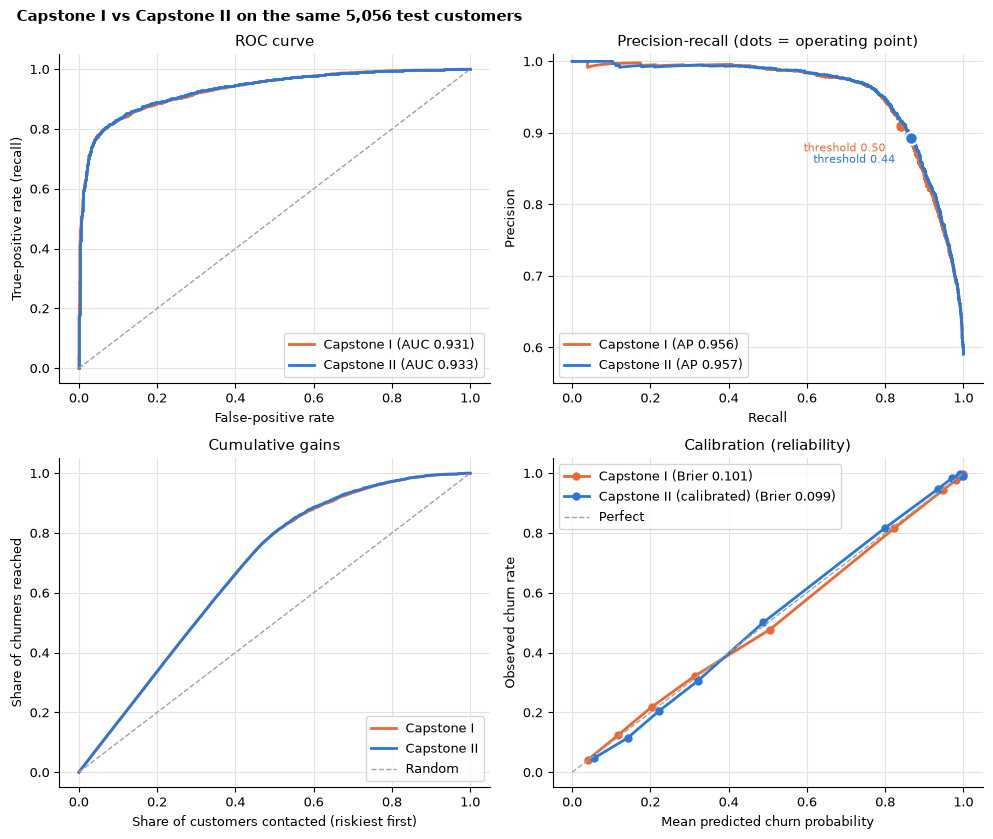

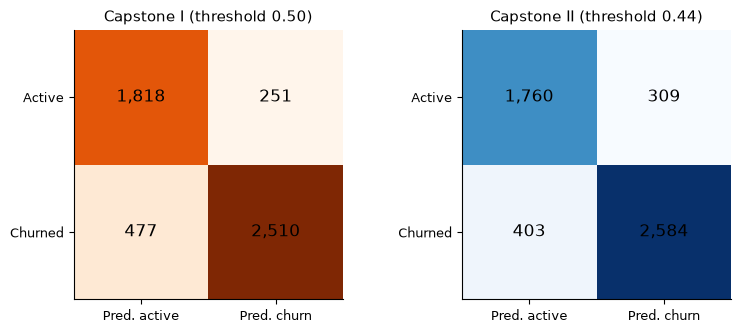

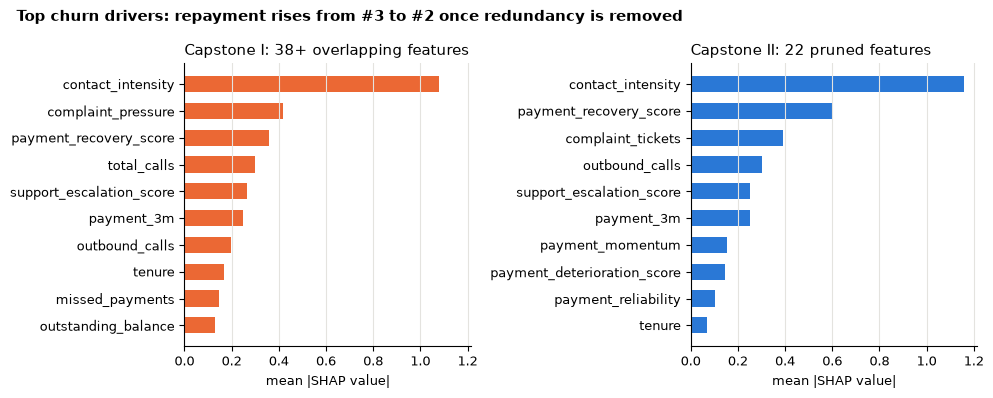

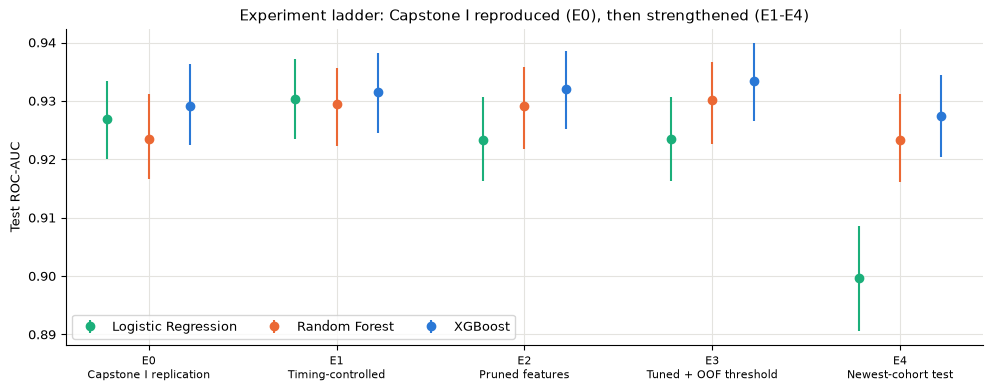

In [13]:

from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, average_precision_score
from sklearn.calibration import calibration_curve

C1, C2, GREY = "#eb6834", "#2a78d6", "#a3a29c"   # Capstone I = orange, Capstone II = blue
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "font.size": 9})

# --- Capstone I-style model on the SAME train/test customers ---
e0i = e0.set_index("customer_id")
X1tr = e0i.loc[train["customer_id"], F0 + CAT]; X1te = e0i.loc[test["customer_id"], F0 + CAT]
capI = make_pipe("XGBoost", F0, CAT).set_params(model__n_estimators=300, model__learning_rate=0.05,
        model__max_depth=7, model__colsample_bytree=0.7, model__gamma=0.3, model__subsample=1.0)
capI.fit(X1tr, ytr)
p1, p2 = capI.predict_proba(X1te)[:, 1], p_raw          # p_raw = Capstone II tuned XGBoost
t1, t2 = 0.5, T
for lab, p, t in [("Capstone I-style", p1, t1), ("Capstone II", p2, t2)]:
    print(lab, {k: round(v, 4) for k, v in score("", "", yte, p, t).items() if k not in ("exp", "model")},
          "| Brier", round(brier_score_loss(yte, p), 4))

# --- Figure A: four curves ---
fig, ax = plt.subplots(2, 2, figsize=(10, 8.5))
# ROC
for lab, p, c in [("Capstone I", p1, C1), ("Capstone II", p2, C2)]:
    f, t_, _ = roc_curve(yte, p); ax[0, 0].plot(f, t_, color=c, lw=2, label=f"{lab} (AUC {roc_auc_score(yte, p):.3f})")
ax[0, 0].plot([0, 1], [0, 1], "--", color=GREY, lw=1); ax[0, 0].set(title="ROC curve", xlabel="False-positive rate", ylabel="True-positive rate (recall)")
ax[0, 0].legend(loc="lower right")
# Precision-recall with operating points
for lab, p, t, c in [("Capstone I", p1, t1, C1), ("Capstone II", p2, t2, C2)]:
    pr, rc, _ = precision_recall_curve(yte, p); ax[0, 1].plot(rc, pr, color=c, lw=2, label=f"{lab} (AP {average_precision_score(yte, p):.3f})")
    yh = p >= t; ax[0, 1].plot(recall_score(yte, yh), precision_score(yte, yh), "o", ms=9, color=c, mec="white", mew=1.5)
    ax[0, 1].annotate(f"threshold {t:.2f}", (recall_score(yte, yh), precision_score(yte, yh)), xytext=(-70, -18), textcoords="offset points", fontsize=8, color=c)
ax[0, 1].set(title="Precision-recall (dots = operating point)", xlabel="Recall", ylabel="Precision", ylim=(0.55, 1.01))
ax[0, 1].legend(loc="lower left")
# Gains
share = np.arange(1, len(yte) + 1) / len(yte)
for lab, p, c in [("Capstone I", p1, C1), ("Capstone II", p2, C2)]:
    o = np.argsort(-p); ax[1, 0].plot(share, np.cumsum(yte[o]) / yte.sum(), color=c, lw=2, label=lab)
ax[1, 0].plot(share, share, "--", color=GREY, lw=1, label="Random")
ax[1, 0].set(title="Cumulative gains", xlabel="Share of customers contacted (riskiest first)", ylabel="Share of churners reached")
ax[1, 0].legend(loc="lower right")
# Calibration
for lab, p, c in [("Capstone I", p1, C1), ("Capstone II (calibrated)", p_cal, C2)]:
    fo, mp = calibration_curve(yte, p, n_bins=10, strategy="quantile"); ax[1, 1].plot(mp, fo, "o-", color=c, lw=2, ms=5, label=f"{lab} (Brier {brier_score_loss(yte, p):.3f})")
ax[1, 1].plot([0, 1], [0, 1], "--", color=GREY, lw=1, label="Perfect")
ax[1, 1].set(title="Calibration (reliability)", xlabel="Mean predicted churn probability", ylabel="Observed churn rate")
ax[1, 1].legend(loc="upper left")
fig.suptitle("Capstone I vs Capstone II on the same 5,056 test customers", fontweight="bold", x=0.02, ha="left")
plt.tight_layout(); plt.savefig("fig_compare_curves.png", dpi=200, bbox_inches="tight"); plt.show()

# --- Figure B: confusion matrices ---
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
for a, (lab, p, t, cmap) in zip(ax, [("Capstone I (threshold 0.50)", p1, t1, "Oranges"), (f"Capstone II (threshold {t2:.2f})", p2, t2, "Blues")]):
    cm = confusion_matrix(yte, p >= t); a.imshow(cm, cmap=cmap); a.grid(False)
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=12, color="black")
    a.set(title=lab, xticks=[0, 1], yticks=[0, 1], xticklabels=["Pred. active", "Pred. churn"], yticklabels=["Active", "Churned"])
plt.tight_layout(); plt.savefig("fig_compare_confusion.png", dpi=200, bbox_inches="tight"); plt.show()

# --- Figure C: SHAP drivers, Capstone I (report) vs Capstone II ---
capI_shap = pd.Series({"contact_intensity": 1.0804, "complaint_pressure": 0.4163, "payment_recovery_score": 0.3594,
    "total_calls": 0.2994, "support_escalation_score": 0.2660, "payment_3m": 0.2486, "outbound_calls": 0.1993,
    "tenure": 0.1686, "missed_payments": 0.1453, "outstanding_balance": 0.1296})
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for a, s, c, t in [(ax[0], capI_shap, C1, "Capstone I: 38+ overlapping features"), (ax[1], imp.head(10), C2, "Capstone II: 22 pruned features")]:
    s = s.iloc[::-1]; a.barh(s.index, s.values, color=c, height=0.6); a.set_title(t, loc="left"); a.grid(axis="y", visible=False)
    a.set_xlabel("mean |SHAP value|")
fig.suptitle("Top churn drivers: repayment rises from #3 to #2 once redundancy is removed", fontweight="bold", x=0.02, ha="left")
plt.tight_layout(); plt.savefig("fig_compare_shap.png", dpi=200, bbox_inches="tight"); plt.show()

# --- Figure D: experiment ladder (AUC with 95% CI) ---
lad = pd.concat([res, e3, pd.DataFrame(e4)]).reset_index(drop=True)
exps = list(dict.fromkeys(lad["exp"])); mc = {"Logistic Regression": "#1baf7a", "Random Forest": C1, "XGBoost": C2}
fig, a = plt.subplots(figsize=(10, 4))
for i, m in enumerate(MODELS):
    r = lad[lad["model"] == m].set_index("exp").reindex(exps); x = np.arange(len(exps)) + (i - 1) * 0.22
    a.errorbar(x, r["auc"], yerr=[r["auc"] - r["auc_lo"], r["auc_hi"] - r["auc"]], fmt="o", color=mc[m], ms=6, elinewidth=1.5, label=m)
a.set_xticks(range(len(exps))); a.set_xticklabels([e.replace(" ", "\n", 1) for e in exps], fontsize=8)
a.set(ylabel="Test ROC-AUC", title="Experiment ladder: Capstone I reproduced (E0), then strengthened (E1-E4)"); a.legend(ncol=3, loc="lower left")
plt.tight_layout(); plt.savefig("fig_experiment_ladder.png", dpi=200, bbox_inches="tight"); plt.show()


- **Figure A:** ROC, precision-recall, cumulative gains and calibration curves for both models.
- **Figure B:** side-by-side confusion matrices showing how many more churners Capstone II catches.
- **Figure C:** top-10 SHAP drivers before and after redundancy pruning.
- **Figure D:** AUC with 95% CIs across the experiment ladder .